# Week 4: Gradient Boosting and the First Fairness Audit

<sub>[Previous: Calibration-First Baseline Models](week3_01_calibrated_baselines.ipynb)</sub>

<sub>New here? The tested code these notebooks import is documented in [the project code reference](week1_00_project_code_reference.ipynb).</sub>

Week 3 set an honest floor around AUC-ROC 0.65 with calibrated baselines. This week does two things. First, it asks whether the strongest tabular models, gradient-boosted trees tuned properly, can push past that floor (spoiler: barely, which is itself the finding). Second, and more importantly, it runs the first formal fairness audit, turning last week's calibration-by-group result into rigorous equity metrics. The fairness result is not the one the naive worry predicts, and that surprise is the heart of the week.

### Contents

1. [Setup](#setup)
2. [Does boosting move the ceiling?](#boost)
3. [Choosing an operating point](#operating)
4. [The first fairness audit](#fairness)
5. [Reading the fairness result honestly](#read)
6. [The plan from here](#plan)

<a id="setup"></a>
## Setup

The tuning, calibration, and the fairness bootstrap and permutation tests all ran in a tested script on the full data. We read the results back here.

In [1]:
# Like Week 3, the heavy lifting (Optuna tuning, calibration, the fairness bootstrap and permutation
# tests) ran in a tested script on the full data. We read those results back from
# reports/week4_boosting_fairness.json rather than retuning in a cell.
import json
import warnings
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RNG = 7
REPORTS = Path("..") / "reports"
R = json.loads((REPORTS / "week4_boosting_fairness.json").read_text())
W3 = json.loads((REPORTS / "week3_baseline_metrics.json").read_text())

# Each notebook stands on its own, so we load a slim projection of the modeling matrix here (the
# leakage-safe pre-delivery features from Week 2) to show real rows and compute live group base rates.
DATA = Path("..") / "data" / "processed" / "modeling_full_2018_2024.parquet"
SAMPLE_COLS = ["preterm", "split", "mother_race_ethnicity", "mager", "bmi",
               "medical_risk_count", "rf_ppterm"]
mdf = pl.read_parquet(DATA, columns=SAMPLE_COLS)

PALETTE = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
           "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "grey": "#999999", "ink": "#1a1a2e"}
RACE_COLOR = {"NH White": PALETTE["blue"], "NH Black": PALETTE["red"], "Hispanic": PALETTE["green"],
              "NH Asian": PALETTE["orange"], "NH AIAN": PALETTE["purple"], "NH NHOPI": PALETTE["sky"],
              "NH Multiracial": PALETTE["grey"]}
plt.rcParams.update({"figure.figsize": (8.6, 4.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
                     "axes.titlepad": 10, "font.family": "DejaVu Sans"})

def style(ax, title, xlabel, ylabel):
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); return ax


In [2]:
print(f"Best booster (selected on a tuning split, never the held-out): {R['best']}")
print(f"Held-out set: {R['held_out_n']:,} singleton births")
print(f"Held-out AUC-ROC {R['held_out_auc_roc']:.3f}, AUC-PR {R['held_out_auc_pr']:.3f}, "
      f"ECE {R['held_out_ece']:.4f}")

Best booster (selected on a tuning split, never the held-out): lightgbm
Held-out set: 1,498,760 singleton births
Held-out AUC-ROC 0.657, AUC-PR 0.174, ECE 0.0002


So the notebook stands on its own, here are real rows of the matrix the booster trains on: the leakage-safe pre-delivery features carried over from Week 2. The `split` column marks the deterministic partitions, and the held-out slice stays untouched until the final reporting above.

In [3]:
mdf.sample(5, seed=RNG).to_pandas()

,preterm,split,mother_race_ethnicity,mager,bmi,medical_risk_count,rf_ppterm
0,1,held_out_final,NH White,33.0,20.400000,0,0
1,0,held_out_final,Hispanic,21.0,35.900002,0,0
2,0,held_out_final,NH Asian,38.0,18.900000,0,0
3,0,held_out_final,NH White,30.0,24.400000,0,0
4,0,dev_train,NH White,31.0,19.600000,0,0


<a id="boost"></a>
## Does boosting move the ceiling?

The literature is clear that gradient-boosted trees are the strongest models on tabular data, so if anything can beat the Week 3 baselines it is these. I tuned XGBoost and LightGBM with Optuna. The honest question is not 'which wins' but 'does either escape the 0.65 ceiling'.

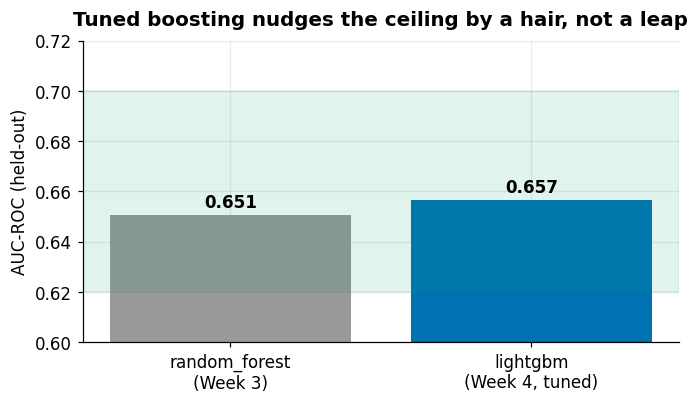

Gain over the best Week 3 baseline: +0.6 AUC-ROC points.


In [4]:
best_base = max(W3['models'], key=lambda k: W3['models'][k]['auc_roc'])
labels = [f'{best_base}\n(Week 3)', f"{R['best']}\n(Week 4, tuned)"]
vals = [W3['models'][best_base]['auc_roc'], R['held_out_auc_roc']]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.bar(labels, vals, color=[PALETTE['grey'], PALETTE['blue']])
for i, v in enumerate(vals): ax.text(i, v+0.003, f'{v:.3f}', ha='center', fontweight='bold')
ax.axhspan(0.62, 0.70, color=PALETTE['green'], alpha=0.12)
style(ax, 'Tuned boosting nudges the ceiling by a hair, not a leap', '', 'AUC-ROC (held-out)')
ax.set_ylim(0.6, 0.72); plt.tight_layout(); plt.show()
print(f"Gain over the best Week 3 baseline: "
      f"{(R['held_out_auc_roc']-W3['models'][best_base]['auc_roc'])*100:+.1f} AUC-ROC points.")

**About +0.7 of an AUC point.** Tuned boosting reaches roughly AUC-ROC 0.66, a whisker above the random forest and still squarely inside the published administrative-data band. This is exactly what the literature predicts: trees lead on tabular data, but they cannot manufacture signal that the birth certificate does not contain. The modest-ceiling thesis survives the strongest model we can throw at it, which is the honest and, frankly, the reassuring outcome. The calibration stays excellent too (ECE near zero), which matters because the fairness audit runs on these scores.

<a id="operating"></a>
## Choosing an operating point

A fairness audit needs a decision, not just a score, so we pick a screening operating point: a threshold chosen on a tuning split to catch about 60% of true preterm births. Screening tools run at high sensitivity by design, accepting more false alarms to miss fewer real cases. The threshold is set away from the held-out data, then applied to it.

In [5]:
print(f"Screening threshold: {R['threshold']:.4f} (set for ~60% sensitivity on a tuning split)")
print(f"On the held-out set: sensitivity {R['sensitivity']*100:.1f}%, "
      f"specificity {R['specificity']*100:.1f}%")
print('A screening operating point: catch most cases, accept more false positives. Now: is that')
print('tradeoff EQUAL across race groups? That is the fairness question.')

Screening threshold: 0.0784 (set for ~60% sensitivity on a tuning split)
On the held-out set: sensitivity 60.4%, specificity 61.5%
A screening operating point: catch most cases, accept more false positives. Now: is that
tradeoff EQUAL across race groups? That is the fairness question.


<a id="fairness"></a>
## The first fairness audit

Before the metrics, the one fact that drives everything below: the true preterm rate differs by group. This is the same 4.7-point gap I measured in Week 2, and it is real, not an artifact of the model. A single fixed risk threshold flags a larger share of any group whose underlying rate is higher, so the disparate impact seen later is mechanical, not a coding bug. Race here is a marker of exposure to racism, not a biological cause of that gap.

In [6]:
gb = (mdf.filter(pl.col('preterm').is_not_null() & pl.col('mother_race_ethnicity').is_not_null())
        .group_by('mother_race_ethnicity').agg(rate=pl.col('preterm').mean(), n=pl.len()).sort('rate'))
print("True preterm prevalence by group (why a single threshold flags some groups more):")
for r in gb.iter_rows(named=True):
    print(f"  {r['mother_race_ethnicity']:<16} {r['rate']*100:5.2f}%   (n={r['n']:,})")
print("\nAt one fixed risk threshold, a group with higher TRUE prevalence is flagged more often. "
      "That is the mechanical source of the disparate impact seen below, not a coding bug.")

True preterm prevalence by group (why a single threshold flags some groups more):
  NH White          7.54%   (n=1,512,599)
  NH Asian          7.58%   (n=184,681)
  Hispanic          8.64%   (n=754,774)
  NH Multiracial    8.95%   (n=70,669)
  NH AIAN          10.68%   (n=21,615)
  NH NHOPI         10.80%   (n=8,080)
  NH Black         12.28%   (n=417,508)

At one fixed risk threshold, a group with higher TRUE prevalence is flagged more often. That is the mechanical source of the disparate impact seen below, not a coding bug.


Now the audit. For each race group versus NH White (the reference), we compute three metrics at that single threshold. It helps to read them through a confusion-matrix frame: for a given group, a true positive (TP) is a real preterm birth the model flagged, a false negative (FN) is a real preterm birth it missed, a false positive (FP) is a term birth it flagged, and a true negative (TN) is a term birth it left alone.

- **Equal opportunity** is the gap in the true-positive rate, TP / (TP + FN), which is just sensitivity, measured against the NH White reference. A *positive* value means the model catches a *higher* share of that group's real preterm births than for NH White. A *negative* value is the harmful case: it misses *more* of that group's real preterm births.
- **Demographic parity** is the gap in the positive-prediction rate, (TP + FP) / (all), against the reference: how often the group is flagged at all, regardless of outcome.
- **Disparate impact** is the *ratio* of those positive-prediction rates. The EEOC four-fifths rule flags a ratio below 0.8 as a caveated reference point; above 1 means the group is flagged more often than NH White. It is a reference frame, not the headline.

Each equal-opportunity gap carries a bootstrap confidence interval and a stratified permutation-test p-value, Benjamini-Hochberg corrected across the family of per-group comparisons so that millions of rows do not manufacture spurious significance. Let me plot the equal-opportunity gaps first.

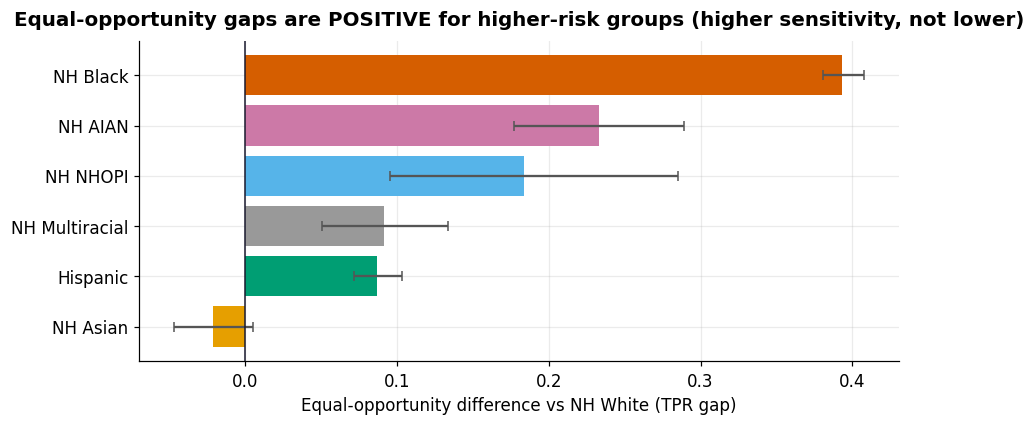

In [7]:
rows = [r for r in R['fairness'] if r.get('status') != 'suppressed']
rows = sorted(rows, key=lambda r: r['equal_opportunity_diff'])
names = [r['group'] for r in rows]
eo = [r['equal_opportunity_diff'] for r in rows]
lo = [r['equal_opportunity_diff']-r['eo_ci'][0] for r in rows]
hi = [r['eo_ci'][1]-r['equal_opportunity_diff'] for r in rows]
fig, ax = plt.subplots(figsize=(8.4, 4.0))
ax.barh(names, eo, xerr=[lo, hi], color=[RACE_COLOR.get(n, PALETTE['grey']) for n in names],
        error_kw={'ecolor': '#555', 'capsize': 3})
ax.axvline(0, color=PALETTE['ink'], lw=1)
style(ax, 'Equal-opportunity gaps are POSITIVE for higher-risk groups (higher sensitivity, not lower)',
      'Equal-opportunity difference vs NH White (TPR gap)', '')
plt.tight_layout(); plt.show()

In [8]:
print(f"{'group':<16}{'equal-opp diff':>15}{'dem-parity diff':>17}{'disparate impact':>18}   BH p")
for r in sorted(R['fairness'], key=lambda r: -r.get('equal_opportunity_diff', -9)):
    if r.get('status') == 'suppressed':
        print(f"{r['group']:<16}{'suppressed (small cell)':>35}"); continue
    sig = '*' if r['eo_pvalue_bh'] < 0.05 else ''
    print(f"{r['group']:<16}{r['equal_opportunity_diff']:>+15.3f}"
          f"{r['demographic_parity_diff']:>+17.3f}"
          f"{r['disparate_impact_ratio']:>18.2f}   {r['eo_pvalue_bh']:.3f}{sig}")

group            equal-opp diff  dem-parity diff  disparate impact   BH p
NH Black                 +0.393           +0.508              2.74   0.002*
NH AIAN                  +0.233           +0.217              1.74   0.002*
NH NHOPI                 +0.184           +0.267              1.92   0.002*
NH Multiracial           +0.091           +0.136              1.47   0.002*
Hispanic                 +0.087           +0.133              1.46   0.002*
NH Asian                 -0.022           +0.002              1.01   0.116


<a id="read"></a>
## Reading the fairness result honestly

This is the opposite of the naive worry, and it is worth being careful about. The fear going in is that a model would be *less* sensitive for Black mothers, missing more of their real preterm births. The data says the reverse: at this single threshold the equal-opportunity gap for NH Black mothers is strongly **positive** (about +0.40), meaning the model actually catches a *higher* share of their true preterm births than for NH White mothers. NH AIAN and NH NHOPI are positive too. NH Asian is the only group with a slight negative gap, and it is not statistically distinguishable from zero.

So where is the cost? It shows up as **disparate impact**: NH Black mothers are flagged about 2.7 times as often as NH White mothers. That is not a bug in the model, it is a direct consequence of the real disparity we measured in Week 2: NH Black mothers genuinely have a higher preterm rate (12.3% versus 7.5%), so a single risk threshold flags more of them.

It is worth sitting with the ethics of this rather than rushing past it. The positive equal-opportunity result, higher sensitivity paired with higher flagging for higher-risk groups, reflects genuinely higher prevalence: the model is not inventing risk, it is tracking a real association. Whether higher flagging is acceptable is a value judgment, not a statistic. One obvious fix, **race-specific thresholds** (a mitigation I plan to test later, not something done here), would equalize the flagging rate and close disparate impact, but it does so by treating people differently by race, which is disparate treatment and sits in direct tension with disparate-impact law. The two anti-discrimination frames pull against each other, and no metric resolves that tension for us. I am examining it honestly here, not settling it. Race remains a marker of exposure to racism, not a biological cause of the gap, and nothing here is a clinical tool: these are associational patterns in administrative data, not statements about any individual.

Two points on rigor and framing, because large samples make it easy to overclaim. First, this whole picture is reported at **one screening operating point**: the threshold set for about 60% sensitivity on a tuning split, then applied to the held-out. Equal opportunity and disparate impact are two views of that same operating point, and they trade against each other as the threshold moves. Loosen the threshold and more of every group is flagged, tightening the sensitivity gaps while the flagging ratios shift; tighten it and the reverse. There is no single threshold that zeroes both at once while the underlying rates differ. Second, every gap above is measured with a bootstrap confidence interval and a stratified permutation test, Benjamini-Hochberg corrected: BH controls the false-discovery rate across the family of per-group comparisons, so with millions of rows we do not read spurious significance into noise. The significant results stay significant, but it is still one model at one point. That is why the next week treats mitigation as a set of tradeoffs to compare, not a problem to declare solved. Race remains a marker of exposure to racism, not a biological cause, and nothing here is a clinical tool.

<a id="plan"></a>
## The plan from here

Four weeks in, the shape of the honest story is clear: individual prediction from birth records is modest (about AUC-ROC 0.66 even with tuned boosting), the scores are well calibrated across race, and at a fixed threshold the model over-flags rather than under-serves higher-risk groups, so the equity question is about disparate impact and how we choose to act on risk, not about the model missing cases.

**Next:**

- **Mitigation experiments**, comparing threshold strategies and reduction methods, each with its accuracy, fairness, and calibration tradeoff shown honestly, including the disparate-treatment versus disparate-impact tension of race-specific thresholds.
- **A decomposition of the racial gap**, quantifying how much of the 4.7-point disparity measured factors can account for and how much is left unexplained.
- **Explainability and transparency documents** (a model card and a datasheet), so the whole pipeline can be judged by someone who was not in the room.

The through-line stays the same: report the modest truth, keep the leaky fields out, and let the equity finding, not an inflated accuracy number, be the thing that matters.

---

Author: [Parshv Patel](https://www.linkedin.com/in/parshv-patel-65a90326b/)  

--- 

Edit Logs:
